# Corpus descriptives

Descriptive analysis of the screened corpus: publication year, document type, subject areas, author keywords, and geography. No sensor or dimension taxonomy: `macro_sensor_types` and `macro_dimensions` are 06_1/06_2 outputs and are not produced by `05b_LLM_Screening.ipynb`. What is observed in the monitoring applications (SQ3) is coded inductively in a later notebook, once the corpus is final.

In [1]:
import json
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import stylecloud
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.labelsize": 14})
plt.rcParams.update({"xtick.labelsize": 12})
plt.rcParams.update({"font.family": "Times New Roman"})

MATTE_COLORS = {
    'blue': '#4f9dc4',
    'red': '#e9785a',
    'teal': '#8ed165',
    'navy': '#3b3d3f',
    'gold': '#f2d156',
    'text': '#333333',
    'pink': '#d97eb8',
    'purple': '#9478d5',
    'grid': '#dddddd',
    'background': '#f7f7f7'
}

c:\Python314\Lib\site-packages\stylecloud\stylecloud.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


## Load data

In [2]:
SCREENED_CORPUS_PATH = "../data/04_llm_screened_corpus.json"
df = pd.read_json(SCREENED_CORPUS_PATH)
print(f"Loaded {len(df)} screened articles from {SCREENED_CORPUS_PATH}")
assert len(df) == 377, f"Expected 377 screened records, found {len(df)}"

Loaded 377 screened articles from ../data/04_llm_screened_corpus.json


## Publications by year

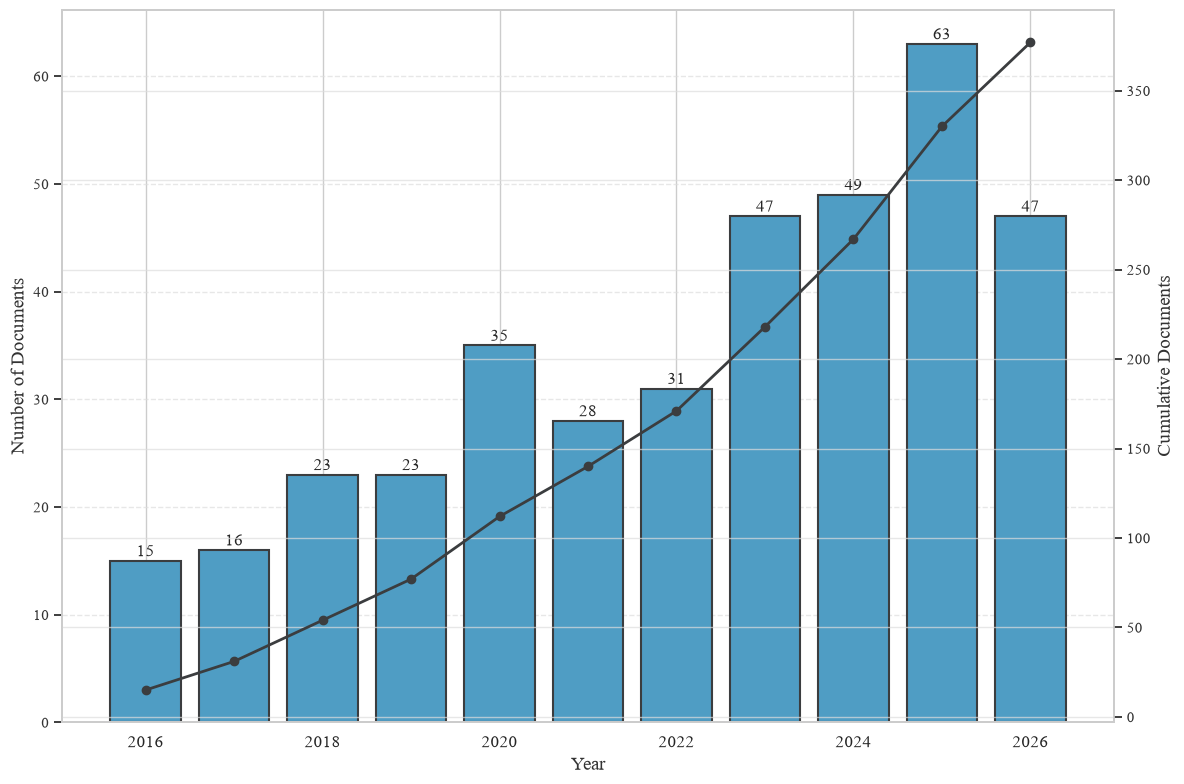

Total documents: 377
Documents with year information: 377
Earliest publication year: 2016
Latest publication year: 2026
Year with most publications: 2025 (63 documents)


In [16]:
years = [d for d in df["publication_date"] if d]
year_counts = Counter(years)

df_years = pd.DataFrame(list(year_counts.items()), columns=["Year", "Count"])
df_years = df_years.sort_values("Year")

fig, ax1 = plt.subplots(figsize=(12, 8))
ax2 = ax1.twinx()

bars = ax1.bar(df_years["Year"], df_years["Count"], color=MATTE_COLORS['blue'],
               edgecolor=MATTE_COLORS['navy'], linewidth=1.5)
ax1.set_xlabel("Year", fontsize=14, color=MATTE_COLORS['text'])
ax1.set_ylabel("Number of Documents", fontsize=14, color=MATTE_COLORS['text'])
ax1.tick_params(axis="y", labelcolor=MATTE_COLORS['text'])

df_years["Cumulative"] = df_years["Count"].cumsum()
line = ax2.plot(df_years["Year"], df_years["Cumulative"], marker="o",
                color=MATTE_COLORS['navy'], linewidth=2)
ax2.set_ylabel("Cumulative Documents", fontsize=14, color=MATTE_COLORS['text'])
ax2.tick_params(axis="y", labelcolor=MATTE_COLORS['text'])

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1,
             f"{height:.0f}", ha="center", va="bottom")

ax1.grid(axis="y", linestyle="--", alpha=0.7, color=MATTE_COLORS['grid'])
ax2.grid(axis="y", linestyle="-", alpha=0.7, color=MATTE_COLORS['grid'])

plt.tight_layout()
plt.show()

print(f"Total documents: {len(df)}")
print(f"Documents with year information: {len(years)}")
print(f"Earliest publication year: {min(years)}")
print(f"Latest publication year: {max(years)}")
print(f"Year with most publications: {year_counts.most_common(1)[0][0]} ({year_counts.most_common(1)[0][1]} documents)")

## Document types

Article, Conference Paper and Book Chapter are the three types the query targets; anything else (should not occur, since Note and Retracted are removed before screening) is grouped as Others.

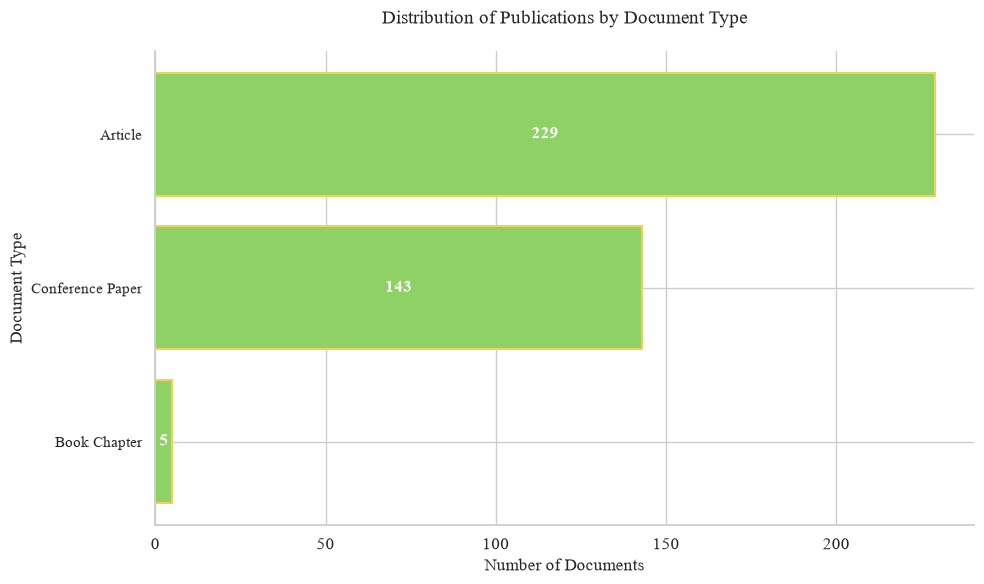

In [17]:
KNOWN_TYPES = ["Article", "Conference Paper", "Book Chapter"]

doc_types = []
for _, doc in df.iterrows():
    doc_type = doc.get("document_type")
    doc_types.append(doc_type if doc_type in KNOWN_TYPES else "Others")

doc_type_counts = Counter(doc_types)
if doc_type_counts.get("Others"):
    print(f"WARNING: {doc_type_counts['Others']} documents outside {KNOWN_TYPES} — check the corpus filter upstream.")

df_doc_types = pd.DataFrame(
    list(doc_type_counts.items()), columns=["Document Type", "Count"]
).sort_values("Count", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    df_doc_types["Document Type"], df_doc_types["Count"],
    color=MATTE_COLORS['teal'], edgecolor=MATTE_COLORS['gold'], linewidth=1.5
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width / 2,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        ha="center", va="center", color="white", fontweight="bold",
    )

ax.set_xlabel("Number of Documents", fontsize=12)
ax.set_ylabel("Document Type", fontsize=12)
ax.set_title("Distribution of Publications by Document Type", fontsize=14, pad=20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Publication sources

This section summarizes the most frequent publication sources (journals) represented in the screened corpus.

Unique publication sources: 204
Documents with source information: 377 out of 377


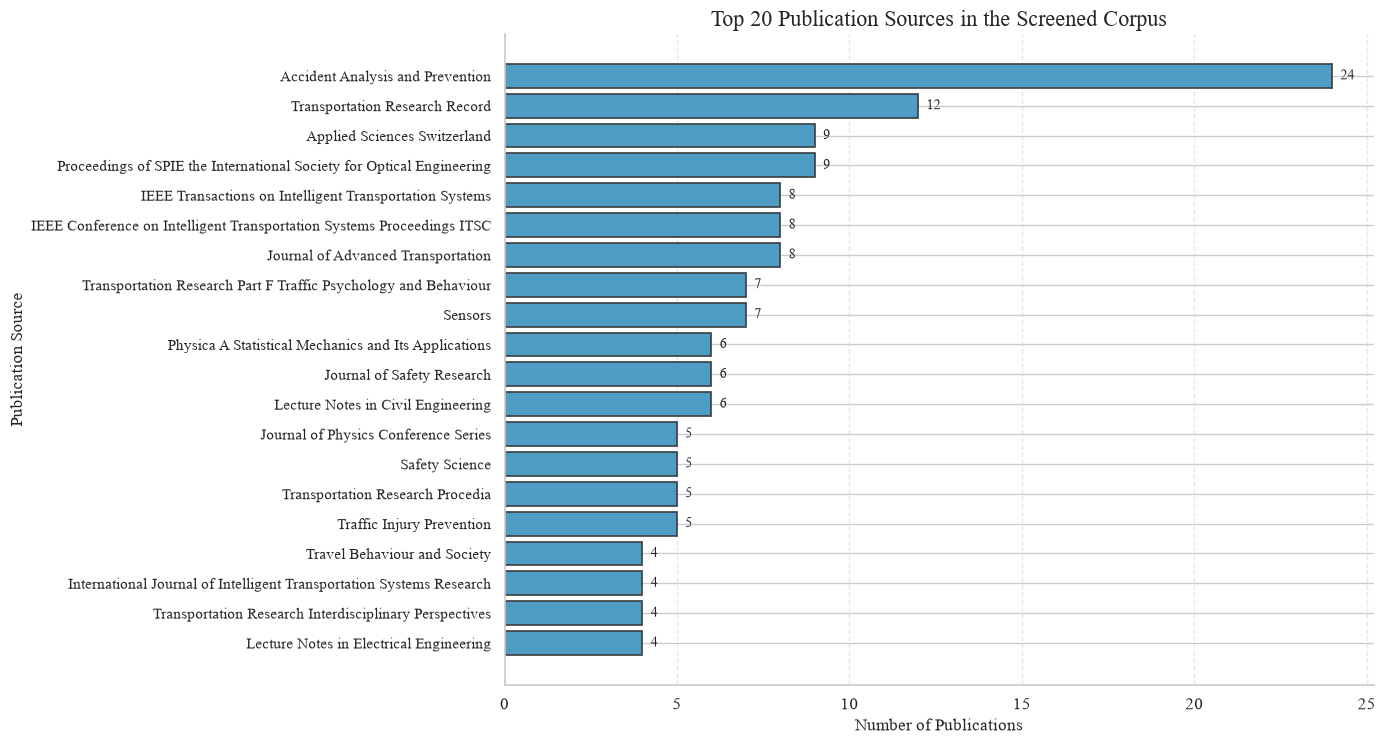

: 

In [ ]:
source_values = df.get("journal", pd.Series(index=df.index, dtype="object"))
sources = (
    source_values.dropna()
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
sources = sources[sources.ne("")]
source_counts = sources.value_counts()

print(f"Unique publication sources: {len(source_counts)}")
print(f"Documents with source information: {len(sources)} out of {len(df)}")

if not source_counts.empty:
    top_sources = source_counts.head(20).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(14, max(6, 0.38 * len(top_sources))))
    bars = ax.barh(
        top_sources.index,
        top_sources.values,
        color=MATTE_COLORS["blue"],
        edgecolor=MATTE_COLORS["navy"],
        linewidth=1.2,
    )

    for bar, count in zip(bars, top_sources.values):
        ax.text(
            count + max(top_sources.values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{count}",
            va="center",
            fontsize=10,
        )

    ax.set_xlabel("Number of Publications", fontsize=12)
    ax.set_ylabel("Publication Source", fontsize=12)
    ax.set_title("Top 20 Publication Sources in the Screened Corpus", fontsize=16)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.7, color=MATTE_COLORS["grid"])
    plt.tight_layout()
    plt.show()
else:
    print("No publication source information was found in the 'journal' column.")

## Subject areas

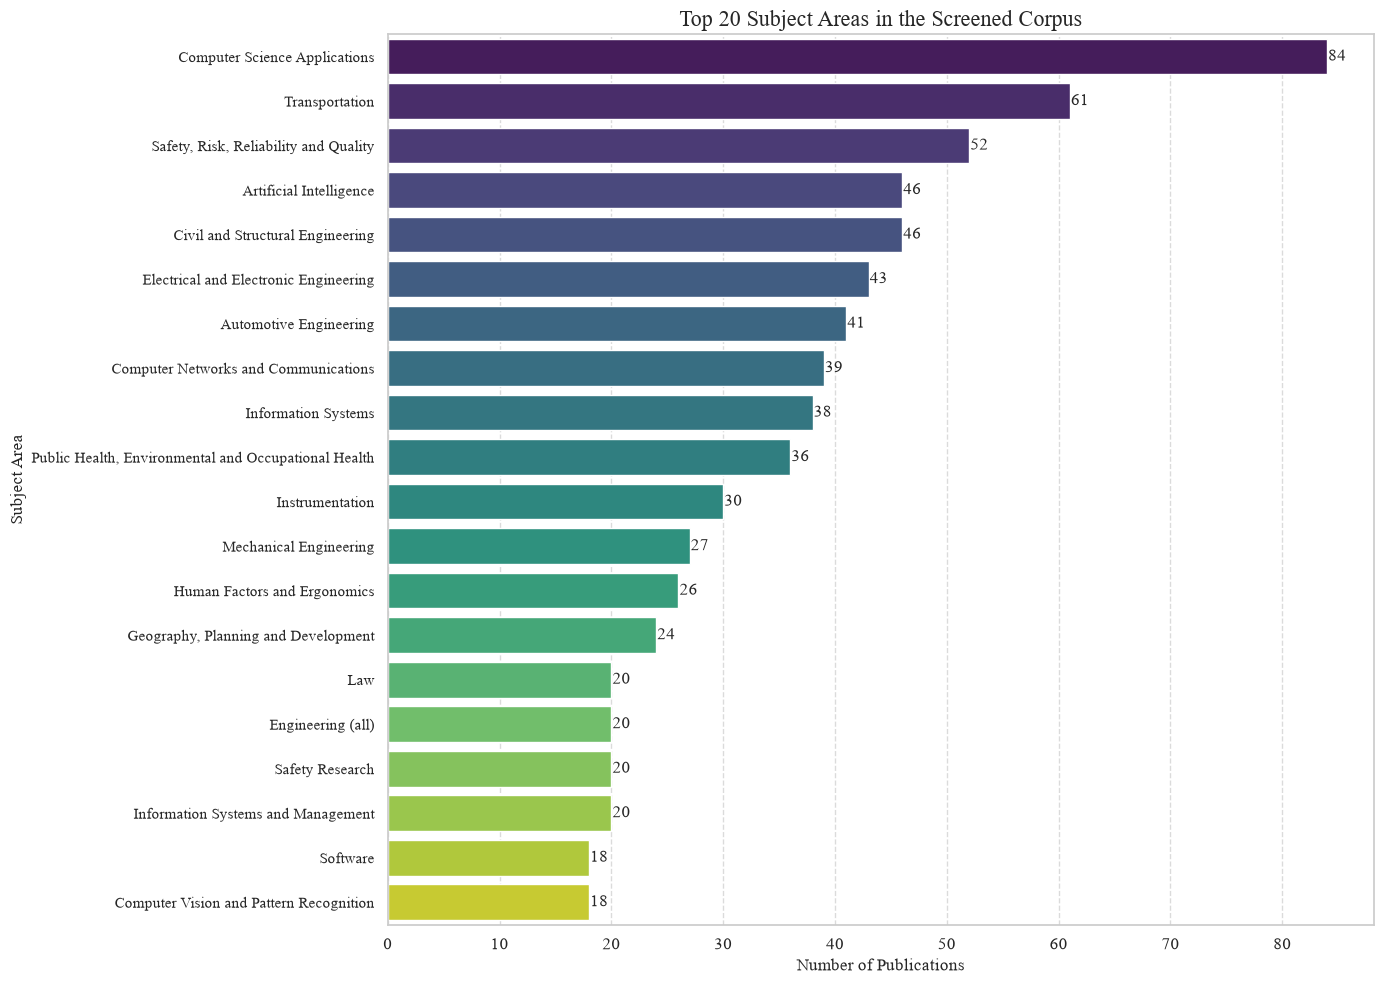



Subject area correlations:


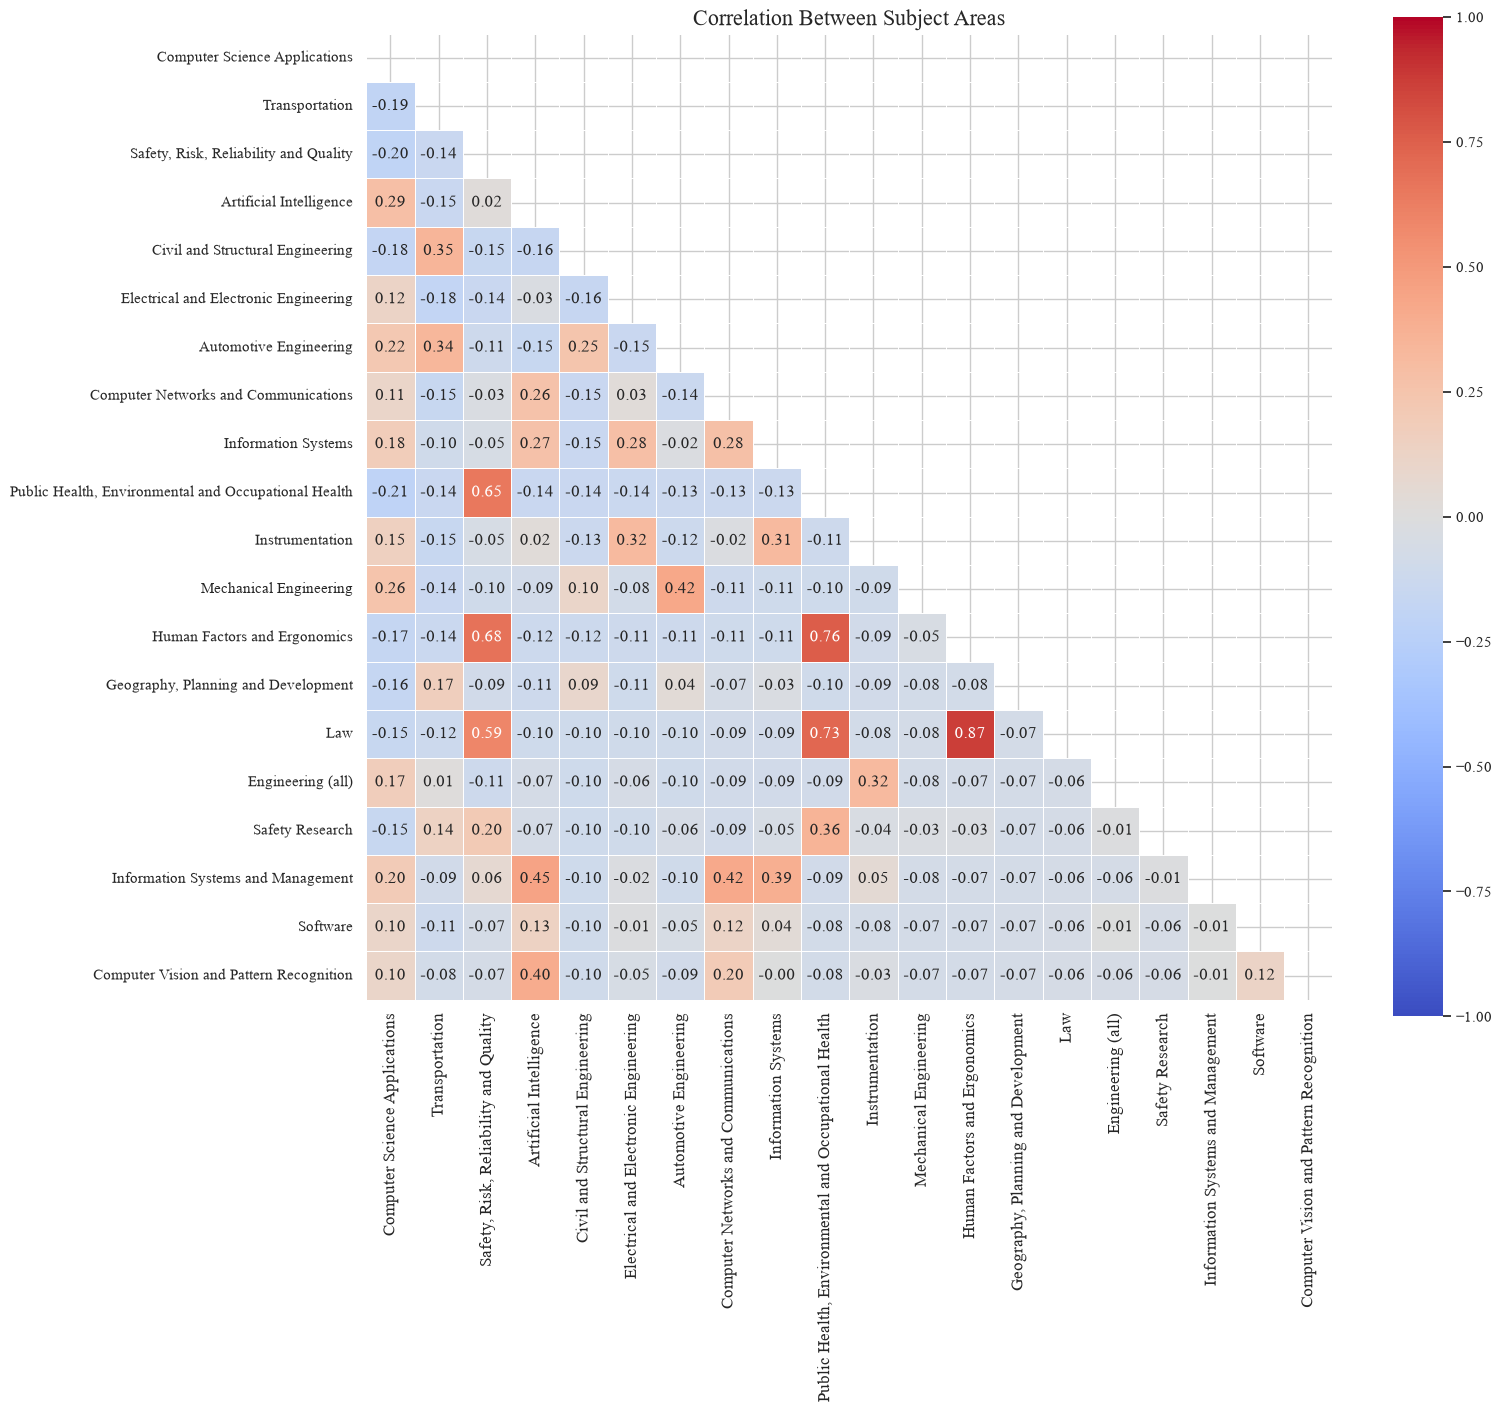


Subject area summary:
Total unique subject areas: 114
Documents with subject area information: 329 out of 377
Average subject areas per document: 3.49

Top 5 most common subject area pairs:
30 - Public Health, Environmental and Occupational Health & Safety, Risk, Reliability and Quality
26 - Artificial Intelligence & Computer Science Applications
26 - Human Factors and Ergonomics & Safety, Risk, Reliability and Quality
24 - Human Factors and Ergonomics & Public Health, Environmental and Occupational Health
24 - Civil and Structural Engineering & Transportation


In [18]:
all_subject_areas = []
subject_area_by_doc = {}

for i, doc in df.reset_index(drop=True).iterrows():
    areas = doc.get("subject_areas")
    if isinstance(areas, list) and areas:
        subject_area_by_doc[i] = areas
        all_subject_areas.extend(areas)

subject_counts = Counter(all_subject_areas)
top_subject_areas = subject_counts.most_common(20)
df_subjects = pd.DataFrame(top_subject_areas, columns=["Subject Area", "Count"])

plt.figure(figsize=(14, 10))
ax = sns.barplot(
    x="Count", y="Subject Area", hue="Subject Area",
    data=df_subjects, palette="viridis", legend=False
)
plt.title("Top 20 Subject Areas in the Screened Corpus", fontsize=16)
plt.xlabel("Number of Publications", fontsize=12)
plt.ylabel("Subject Area", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)

for i, v in enumerate(df_subjects["Count"]):
    ax.text(v + 0.1, i, str(v), va="center")

plt.tight_layout()
plt.show()

print("\n\nSubject area correlations:")

unique_areas = [area for area, _ in top_subject_areas]
doc_subject_matrix = pd.DataFrame(0, index=range(len(subject_area_by_doc)), columns=unique_areas)

for pos, (doc_idx, areas) in enumerate(subject_area_by_doc.items()):
    for area in areas:
        if area in unique_areas:
            doc_subject_matrix.loc[pos, area] = 1

correlation_matrix = doc_subject_matrix.corr()

plt.figure(figsize=(16, 14))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(
    correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f",
    mask=mask, vmin=-1, vmax=1, square=True, linewidths=0.5,
)
plt.title("Correlation Between Subject Areas", fontsize=16)
plt.tight_layout()
plt.show()

print("\nSubject area summary:")
print(f"Total unique subject areas: {len(subject_counts)}")
print(f"Documents with subject area information: {len(subject_area_by_doc)} out of {len(df)}")

areas_per_doc = [len(areas) for areas in subject_area_by_doc.values()]
print(f"Average subject areas per document: {sum(areas_per_doc)/len(areas_per_doc):.2f}")

print("\nTop 5 most common subject area pairs:")
pair_counts = Counter()
for areas in subject_area_by_doc.values():
    for pair in combinations(sorted(areas), 2):
        pair_counts[pair] += 1

for pair, count in pair_counts.most_common(5):
    print(f"{count:2d} - {pair[0]} & {pair[1]}")

## Author keywords

Total unique keywords: 1103


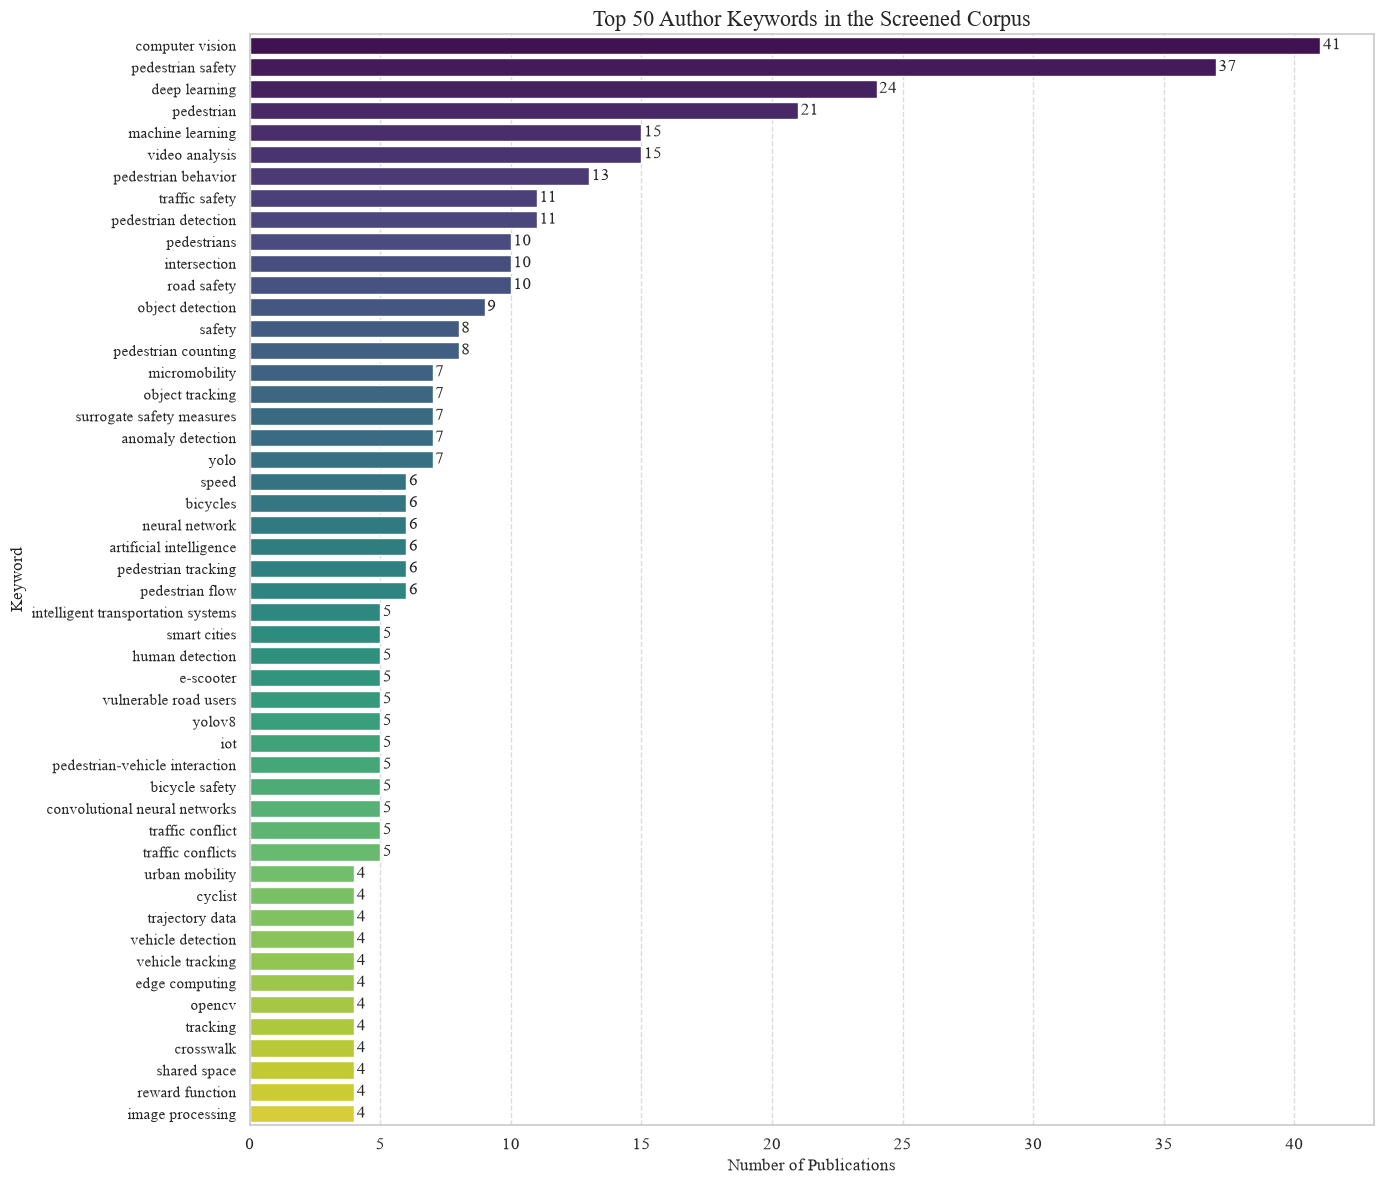

In [3]:
all_keywords = []
keywords_by_doc = {}
keyword_to_articles = {}

for i, doc in df.reset_index(drop=True).iterrows():
    kws = doc.get("author_keywords")
    if isinstance(kws, list) and kws:
        keywords = [kw.lower().strip() for kw in kws]
        keywords_by_doc[i] = keywords
        all_keywords.extend(keywords)
        for kw in keywords:
            keyword_to_articles.setdefault(kw, []).append(doc["title"])

keyword_counts = Counter(all_keywords)
print(f"Total unique keywords: {len(keyword_counts)}")

top_keywords = keyword_counts.most_common(50)
df_keywords = pd.DataFrame(top_keywords, columns=["Keyword", "Count"])

plt.figure(figsize=(14, 12))
ax = sns.barplot(x="Count", y="Keyword", data=df_keywords, hue="Keyword",
                 palette="viridis", dodge=False, legend=False)
plt.title("Top 50 Author Keywords in the Screened Corpus", fontsize=16)
plt.xlabel("Number of Publications", fontsize=12)
plt.ylabel("Keyword", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)

for i, v in enumerate(df_keywords["Count"]):
    ax.text(v + 0.1, i, str(v), va="center")

plt.tight_layout()
plt.show()

## Keyword word cloud

Saved fas fa-camera word cloud to ..\figures\author_keywords_camera.png


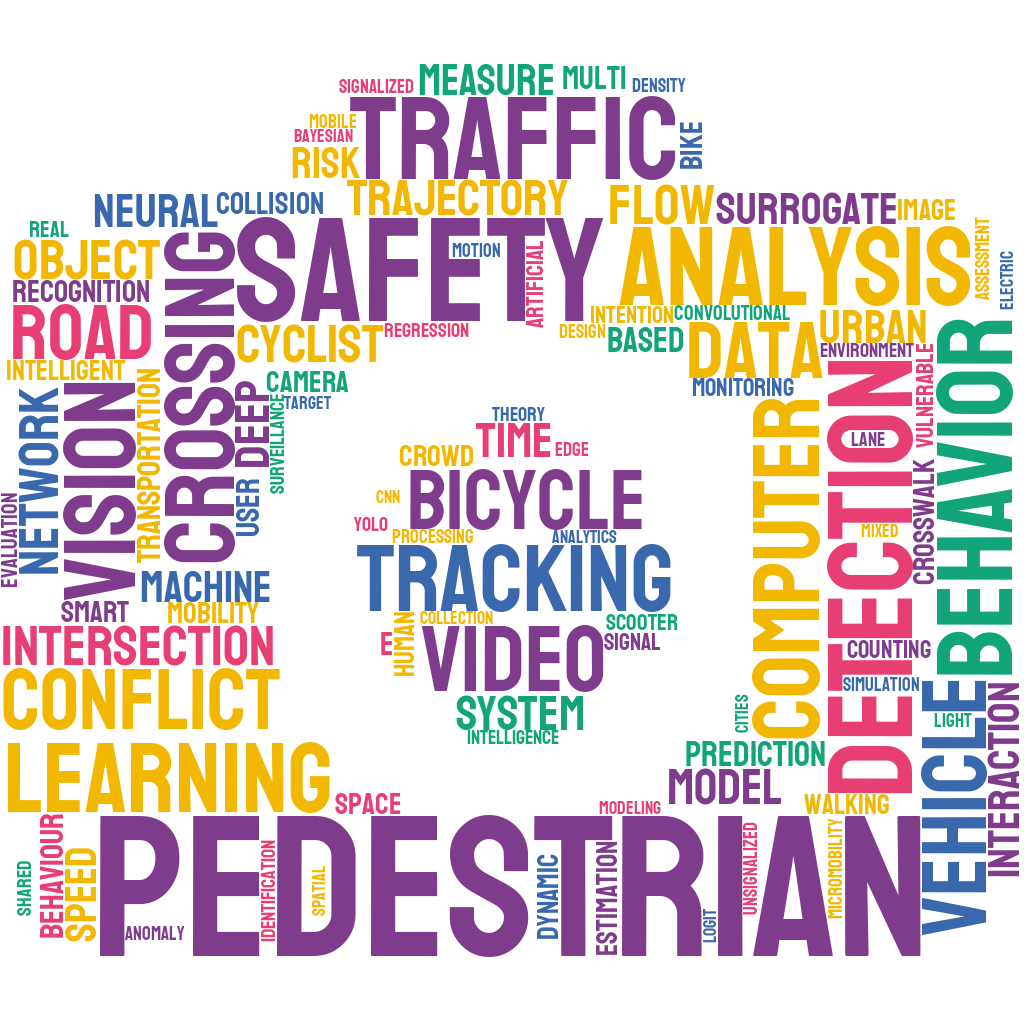

Saved fas fa-eye word cloud to ..\figures\author_keywords_eye.png


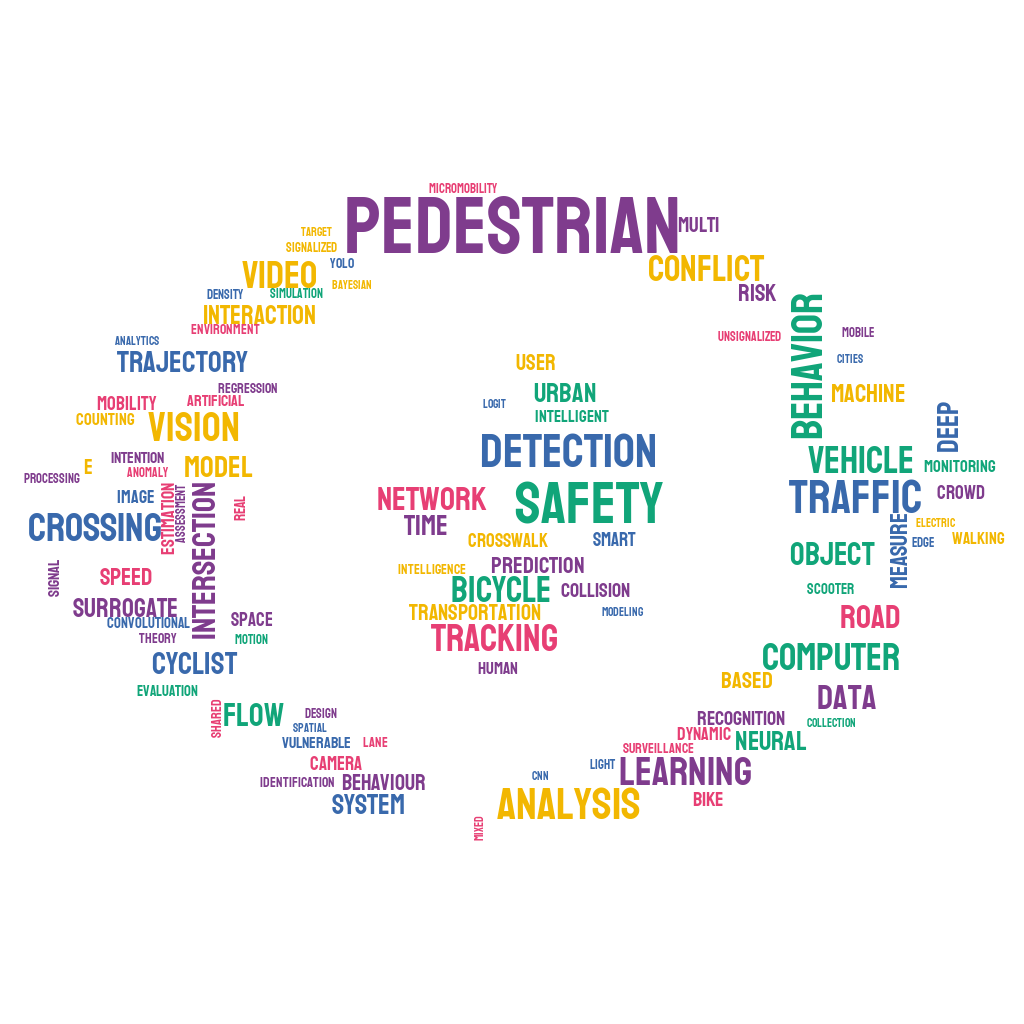

In [5]:
# StyleCloud's icon renderer still calls ImageDraw.textsize, removed in Pillow 10+.
from PIL import ImageDraw

if not hasattr(ImageDraw.ImageDraw, "textsize"):
    def _textsize_compat(self, text, font=None, *args, **kwargs):
        left, top, right, bottom = self.textbbox((0, 0), text, font=font, *args, **kwargs)
        return right - left, bottom - top

    ImageDraw.ImageDraw.textsize = _textsize_compat

# StyleCloud accepts text, so repeat each author keyword according to its corpus frequency.
keyword_text = " ".join(
    keyword
    for keyword, count in keyword_counts.items()
    for _ in range(count)
)
cloud_dir = Path("../figures")
cloud_dir.mkdir(parents=True, exist_ok=True)

cloud_specs = [
    ("fas fa-camera", cloud_dir / "author_keywords_camera.png"),
    ("fas fa-eye", cloud_dir / "author_keywords_eye.png"),
]
for icon_name, output_path in cloud_specs:
    stylecloud.gen_stylecloud(
        text=keyword_text,
        icon_name=icon_name,
        palette="cartocolors.qualitative.Bold_5",
        background_color="white",
        max_words=100,
        collocations=False,
        size=1024,
        output_name=str(output_path),
    )
    print(f"Saved {icon_name} word cloud to {output_path}")
    display(Image(filename=str(output_path)))

## Keyword co-occurrence and correlation

In [21]:
unique_keywords = [kw for kw, _ in keyword_counts.most_common(40)]

doc_keyword_matrix = pd.DataFrame(0, index=range(len(keywords_by_doc)), columns=unique_keywords)
for pos, (doc_idx, kws) in enumerate(keywords_by_doc.items()):
    for kw in kws:
        if kw in unique_keywords:
            doc_keyword_matrix.loc[pos, kw] = 1

doc_keyword_matrix = doc_keyword_matrix.fillna(0).astype(int)

cooccurrence_matrix = doc_keyword_matrix.T.dot(doc_keyword_matrix)

# Use a writable copy to clear self-co-occurrences.
cooccurrence_array = cooccurrence_matrix.to_numpy(copy=True)
np.fill_diagonal(cooccurrence_array, 0)
cooccurrence_matrix = pd.DataFrame(
    cooccurrence_array,
    index=cooccurrence_matrix.index,
    columns=cooccurrence_matrix.columns,
)

print("\nTop 10 co-occurring keyword pairs:")
cooccur_pairs = []
for kw1 in unique_keywords:
    for kw2 in unique_keywords:
        if kw1 < kw2:
            cooccur_pairs.append((kw1, kw2, cooccurrence_matrix.loc[kw1, kw2]))

cooccur_pairs.sort(key=lambda x: x[2], reverse=True)
for kw1, kw2, count in cooccur_pairs[:10]:
    print(f"{kw1} + {kw2}: {count:.0f} co-occurrences")


Top 10 co-occurring keyword pairs:
computer vision + pedestrian safety: 7 co-occurrences
computer vision + deep learning: 5 co-occurrences
computer vision + pedestrian detection: 5 co-occurrences
computer vision + pedestrian tracking: 4 co-occurrences
pedestrian detection + pedestrian tracking: 4 co-occurrences
computer vision + pedestrian: 3 co-occurrences
computer vision + yolo: 3 co-occurrences
computer vision + smart cities: 3 co-occurrences
computer vision + convolutional neural networks: 3 co-occurrences
deep learning + pedestrian safety: 3 co-occurrences


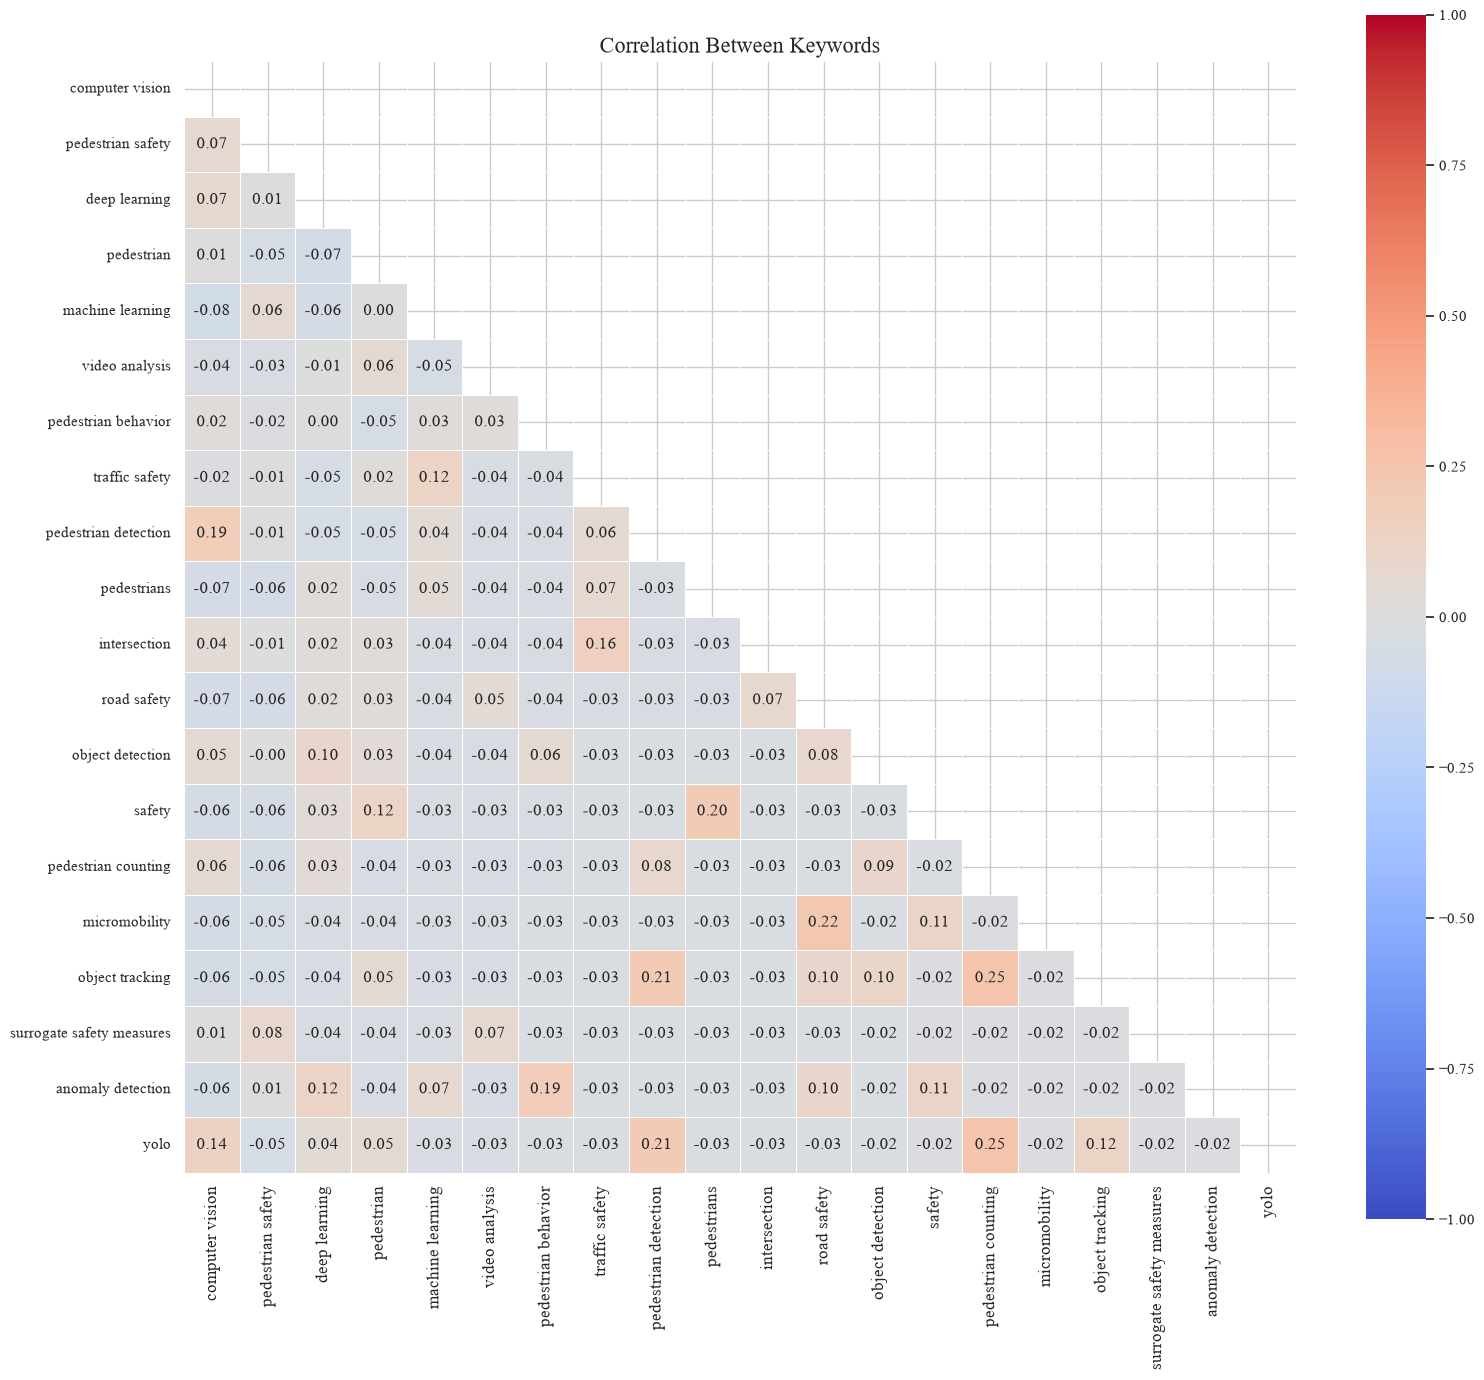

In [22]:
top20_keywords = [kw for kw, _ in keyword_counts.most_common(20)]
correlation_matrix = doc_keyword_matrix[top20_keywords].corr()

plt.figure(figsize=(16, 14))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(
    correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f",
    mask=mask, vmin=-1, vmax=1, square=True, linewidths=0.5,
)
plt.title("Correlation Between Keywords", fontsize=16)
plt.tight_layout()
plt.show()

## Geographic distribution

Maps affiliation countries for the 377 records in the screened corpus. Plotly is retained for its interactive hover details; a separate cartographic library is not needed for this choropleth.

In [6]:
scopus_data = json.load(open('../data/01_scopus_results.json', encoding='utf-8'))


def normalize_doi(doi):
    if not doi or not isinstance(doi, str):
        return None
    return doi.strip().lower().removeprefix('https://doi.org/').removeprefix('http://doi.org/')


def get_raw_doi(article):
    for key in ('doi', 'prism:doi', 'DOI', 'Doi'):
        if article.get(key):
            return article[key]
    return None


doi_to_countries = {}
for scopus_article in scopus_data:
    doi = normalize_doi(get_raw_doi(scopus_article))
    if not doi:
        continue
    affiliations = scopus_article.get('affiliation')
    if not affiliations:
        continue
    if not isinstance(affiliations, list):
        affiliations = [affiliations]
    countries = {
        aff['affiliation-country']
        for aff in affiliations
        if isinstance(aff, dict) and aff.get('affiliation-country')
    }
    if countries:
        doi_to_countries.setdefault(doi, set()).update(countries)

corpus_dois = df["doi"].dropna().apply(normalize_doi)
n_matched = int(corpus_dois.isin(doi_to_countries).sum())
n_total = len(df)
print(f"Articles with matched country data: {n_matched}/{n_total} "
      f"({n_matched / n_total * 100:.1f}%)")
if n_matched < n_total:
    print(f"  {n_total - n_matched} articles have no country data (missing/unmatched DOI) "
          f"and are excluded from the map.")

country_to_docs = Counter()
for doi in corpus_dois:
    if doi in doi_to_countries:
        for country in doi_to_countries[doi]:
            country_to_docs[country] += 1

country_counts = country_to_docs.most_common()
print(f"\nTotal countries: {len(country_counts)}")
print("\nTop 15 countries:")
for country, count in country_counts[:15]:
    print(f"{country}: {count}")

Articles with matched country data: 374/377 (99.2%)
  3 articles have no country data (missing/unmatched DOI) and are excluded from the map.

Total countries: 53

Top 15 countries:
China: 108
United States: 64
India: 27
Canada: 26
Japan: 19
Germany: 15
Australia: 14
South Korea: 12
Italy: 10
Sweden: 6
United Kingdom: 6
Taiwan: 5
Egypt: 4
Russian Federation: 4
Malaysia: 4


In [7]:
import plotly.graph_objects as go

country_name_mapping = {
    'China': 'CHN', 'United States': 'USA', 'India': 'IND', 'Brazil': 'BRA',
    'United Kingdom': 'GBR', 'Germany': 'DEU', 'France': 'FRA', 'Japan': 'JPN',
    'South Korea': 'KOR', 'Canada': 'CAN', 'Australia': 'AUS', 'Italy': 'ITA',
    'Spain': 'ESP', 'Netherlands': 'NLD', 'Singapore': 'SGP', 'Taiwan': 'TWN',
    'Hong Kong': 'HKG', 'Thailand': 'THA', 'South Africa': 'ZAF', 'Mexico': 'MEX',
    'Malaysia': 'MYS', 'Indonesia': 'IDN', 'Philippines': 'PHL', 'Vietnam': 'VNM',
    'Viet Nam': 'VNM', 'Chile': 'CHL', 'Argentina': 'ARG', 'Colombia': 'COL',
    'Greece': 'GRC', 'Portugal': 'PRT', 'Sweden': 'SWE', 'Norway': 'NOR',
    'Denmark': 'DNK', 'Finland': 'FIN', 'Belgium': 'BEL', 'Switzerland': 'CHE',
    'Austria': 'AUT', 'Poland': 'POL', 'Czech Republic': 'CZE', 'Russia': 'RUS',
    'Russian Federation': 'RUS', 'Turkey': 'TUR', 'Israel': 'ISR', 'Saudi Arabia': 'SAU',
    'UAE': 'ARE', 'New Zealand': 'NZL', 'Ireland': 'IRL', 'Pakistan': 'PAK',
    'Bangladesh': 'BGD', 'Egypt': 'EGY', 'Nigeria': 'NGA', 'Kenya': 'KEN',
    'Peru': 'PER', 'Ecuador': 'ECU', 'Bolivia': 'BOL', 'Paraguay': 'PRY',
    'Uruguay': 'URY', 'Costa Rica': 'CRI', 'Panama': 'PAN', 'Guatemala': 'GTM',
    'El Salvador': 'SLV', 'Honduras': 'HND', 'Nicaragua': 'NIC', 'Dominican Republic': 'DOM',
    'Cuba': 'CUB', 'Jamaica': 'JAM', 'Trinidad and Tobago': 'TTO', 'Bahamas': 'BHS',
    'Barbados': 'BRB', 'Iran': 'IRN', 'Macao': 'MAC', 'Ghana': 'GHA',
    'Hungary': 'HUN', 'Iraq': 'IRQ', 'Uganda': 'UGA', 'Algeria': 'DZA',
    'Slovakia': 'SVK', 'Estonia': 'EST', 'Romania': 'ROU', 'Rwanda': 'RWA',
    'Lithuania': 'LTU', 'Morocco': 'MAR', 'Latvia': 'LVA', 'Ukraine': 'UKR',
    'Cyprus': 'CYP', 'Kuwait': 'KWT', 'Ethiopia': 'ETH', 'Bulgaria': 'BGR',
    'Sri Lanka': 'LKA', 'Slovenia': 'SVN', 'Croatia': 'HRV', 'Kazakhstan': 'KAZ',
    'Tunisia': 'TUN', 'Madagascar': 'MDG',
}

countries_list = [country for country, _ in country_counts]
counts_list = [count for _, count in country_counts]
filtered_countries, filtered_counts, filtered_iso = [], [], []
unmapped_countries = []
for country, count in zip(countries_list, counts_list):
    iso = country_name_mapping.get(country)
    if iso:
        filtered_countries.append(country)
        filtered_counts.append(count)
        filtered_iso.append(iso)
    else:
        unmapped_countries.append(country)

if unmapped_countries:
    print(f"Countries not in mapping: {unmapped_countries}")
print(f"\nMapped {len(filtered_iso)} countries to ISO codes")

Countries not in mapping: ['Afghanistan', 'United Arab Emirates', 'Palestine', 'Qatar']

Mapped 49 countries to ISO codes


In [ ]:
fig = go.Figure(data=go.Choropleth(
    locations=filtered_iso,
    z=filtered_counts,
    text=filtered_countries,
    colorscale="Viridis",
    zmin=0,
    zmax=100,
    marker_line_color="darkgray",
    marker_line_width=0.5,
    colorbar={
        "title": {"text": "Articles"},
        "tickmode": "array",
        "tickvals": [0, 100],
        "ticktext": ["0", "100"],
        "orientation": "h",
        "x": 0.5,
        "xanchor": "center",
        "y": -0.12,
        "yanchor": "top",
        "len": 0.6,
        "thickness": 14,
    },
    hovertemplate="<b>%{text}</b><br>Articles: %{z}<extra></extra>",
))

fig.update_layout(
    title={"text": "Articles by Affiliation Country", "x": 0.5},
    geo=dict(
        showland=True,
        landcolor="rgb(243, 243, 243)",
        coastlinecolor="rgb(204, 204, 204)",
        projection_type="natural earth",
        showocean=True,
        oceancolor="rgb(230, 245, 255)",
        showcountries=True,
        countrycolor="rgb(204, 204, 204)",
    ),
    height=650,
    width=1200,
    margin={"l": 20, "r": 20, "t": 70, "b": 100},
    font={"family": "Times New Roman", "size": 12},
)

fig.show()

print(f"\nArticle-country occurrences shown on map: {sum(filtered_counts)}")
print(f"Articles with at least one mapped country: {n_matched} of {n_total} screened articles")
print(f"Number of countries represented: {len(filtered_iso)}")


Article-country occurrences shown on map: 387
Articles with at least one mapped country: 374 of 377 screened articles
Number of countries represented: 49


: 

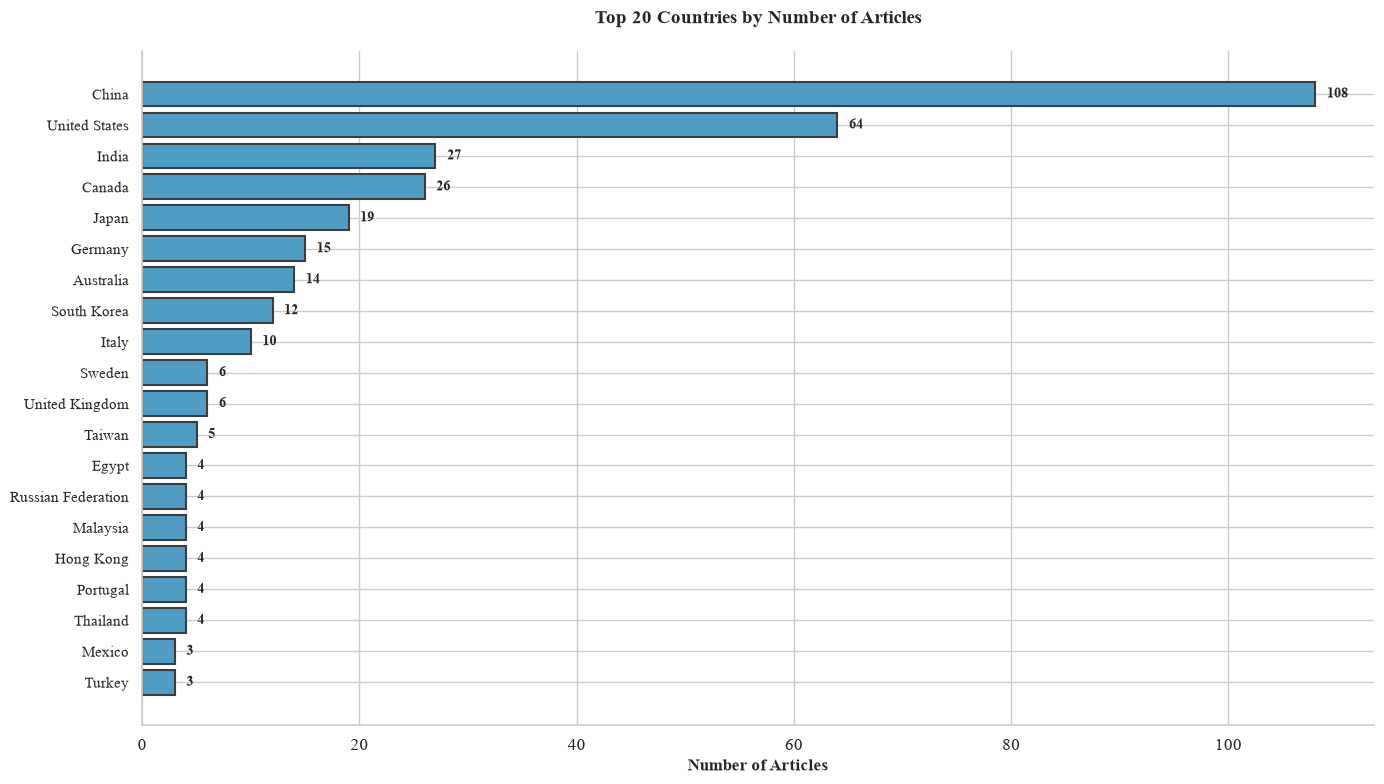


Country summary:
Median articles per country: 2.0
Mean articles per country: 7.4
Std dev: 17.2


In [26]:
fig, ax = plt.subplots(figsize=(14, 8))

top_n = 20
top_countries = sorted(country_to_docs.items(), key=lambda x: x[1], reverse=True)[:top_n]
countries_names = [c[0] for c in top_countries]
counts = [c[1] for c in top_countries]

bars = ax.barh(countries_names, counts, color=MATTE_COLORS['blue'], edgecolor=MATTE_COLORS['navy'], linewidth=1.5)

for i, (bar, count) in enumerate(zip(bars, counts)):
    ax.text(count + max(counts) * 0.01, i, str(count), va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Number of Articles', fontsize=12, fontweight='bold')
ax.set_title(f'Top {top_n} Countries by Number of Articles', fontsize=14, fontweight='bold', pad=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(f"\nCountry summary:")
print(f"Median articles per country: {np.median(list(country_to_docs.values())):.1f}")
print(f"Mean articles per country: {np.mean(list(country_to_docs.values())):.1f}")
print(f"Std dev: {np.std(list(country_to_docs.values())):.1f}")